# Supply Chain Exploratory Data Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
# Load the supply chain dataset
try:
    df = pd.read_csv('../data/order_lines_extended.csv')
except FileNotFoundError:
    df = pd.read_csv('data/order_lines_extended.csv')

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset Shape: 180,519 rows x 44 columns


,transaction_type,days_for_shipping_real,days_for_shipment_scheduled,sales_per_customer,delivery_status,late_delivery_risk,category_name,customer_segment,department_id,department_name,market,order_city,order_country,order_date,order_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,product_card_id,product_category_id,product_name,product_price,product_status,shipping_date,shipping_mode,order_week_start,simulation_primary_supplier_id,simulation_primary_supplier_name,simulation_primary_supplier_nominal_lead_time_days,simulation_reference_unit_cost,simulation_estimated_procurement_cost,simulation_estimated_merchandise_profit_pre_logistics,simulation_estimated_merchandise_margin_pct_pre_logistics,source_provenance,simulation_provenance
0,CASH,2,4,239.979996,Advance shipping,0,Camping & Hiking,Consumer,7,Fan Shop,LATAM,Mexico City,México,2015-01-01 00:00:00,1,60.0,0.20,1,299.980011,0.37,1,299.980011,239.979996,88.790001,Central America,Distrito Federal,CLOSED,957,43,Diamondback Women's Serene Classic Comfort Bi,299.980011,0,2015-01-03 00:00:00,Standard Class,2014-12-29,SIM-SUP-009,Simulated Supplier 09,11,210.87,210.87,29.11,0.121302,OBSERVED_DATACO_ORDER_LINE,SIMULATED_NOT_OBSERVED
1,PAYMENT,3,4,193.990005,Advance shipping,0,Water Sports,Consumer,7,Fan Shop,LATAM,Dos Quebradas,Colombia,2015-01-01 00:21:00,2,6.0,0.03,2,199.990005,0.47,1,199.990005,193.990005,91.180000,South America,Risaralda,PENDING_PAYMENT,1073,48,Pelican Sunstream 100 Kayak,199.990005,0,2015-01-04 00:21:00,Standard Class,2014-12-29,SIM-SUP-004,Simulated Supplier 04,7,143.64,143.64,50.35,0.259549,OBSERVED_DATACO_ORDER_LINE,SIMULATED_NOT_OBSERVED
2,PAYMENT,3,4,227.500000,Advance shipping,0,Women's Apparel,Consumer,5,Golf,LATAM,Dos Quebradas,Colombia,2015-01-01 00:21:00,2,22.5,0.09,3,50.000000,0.30,5,250.000000,227.500000,68.250000,South America,Risaralda,PENDING_PAYMENT,502,24,Nike Men's Dri-FIT Victory Golf Polo,50.000000,0,2015-01-04 00:21:00,Standard Class,2014-12-29,SIM-SUP-002,Simulated Supplier 02,8,35.19,175.95,51.55,0.226593,OBSERVED_DATACO_ORDER_LINE,SIMULATED_NOT_OBSERVED
3,PAYMENT,3,4,107.889999,Advance shipping,0,Men's Footwear,Consumer,4,Apparel,LATAM,Dos Quebradas,Colombia,2015-01-01 00:21:00,2,22.1,0.17,4,129.990005,0.34,1,129.990005,107.889999,36.470001,South America,Risaralda,PENDING_PAYMENT,403,18,Nike Men's CJ Elite 2 TD Football Cleat,129.990005,0,2015-01-04 00:21:00,Standard Class,2014-12-29,SIM-SUP-001,Simulated Supplier 01,12,87.98,87.98,19.91,0.184540,OBSERVED_DATACO_ORDER_LINE,SIMULATED_NOT_OBSERVED
4,CASH,5,4,40.980000,Late delivery,1,Accessories,Home Office,6,Outdoors,LATAM,Dos Quebradas,Colombia,2015-01-01 01:03:00,4,9.0,0.18,5,24.990000,0.10,2,49.980000,40.980000,4.100000,South America,Risaralda,CLOSED,897,40,Team Golf New England Patriots Putter Grip,24.990000,0,2015-01-06 01:03:00,Standard Class,2014-12-29,SIM-SUP-003,Simulated Supplier 03,15,17.07,34.14,6.84,0.166911,OBSERVED_DATACO_ORDER_LINE,SIMULATED_NOT_OBSERVED


In [3]:
# Inspect column data types and completeness
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 44 columns):
 #   Column                                                     Non-Null Count   Dtype  
---  ------                                                     --------------   -----  
 0   transaction_type                                           180519 non-null  object 
 1   days_for_shipping_real                                     180519 non-null  int64  
 2   days_for_shipment_scheduled                                180519 non-null  int64  
 3   sales_per_customer                                         180519 non-null  float64
 4   delivery_status                                            180519 non-null  object 
 5   late_delivery_risk                                         180519 non-null  int64  
 6   category_name                                              180519 non-null  object 
 7   customer_segment                                           180519 non-null  object 

In [4]:
# Summary statistics for primary transaction metrics
numeric_cols = [
    'order_item_quantity', 'order_item_product_price', 'sales',
    'order_item_discount', 'order_item_discount_rate', 'order_item_total',
    'order_profit_per_order', 'days_for_shipping_real', 'days_for_shipment_scheduled'
]
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
order_item_quantity,180519.0,2.127638,1.453451,1.00000,1.000000,1.000000,3.000000,5.000000
order_item_product_price,180519.0,141.232550,139.732492,9.99000,50.000000,59.990002,199.990005,1999.989990
sales,180519.0,203.772096,132.273077,9.99000,119.980003,199.919998,299.950012,1999.989990
order_item_discount,180519.0,20.664741,21.800901,0.00000,5.400000,14.000000,29.990000,500.000000
order_item_discount_rate,180519.0,0.101668,0.070415,0.00000,0.040000,0.100000,0.160000,0.250000
order_item_total,180519.0,183.107609,120.043670,7.49000,104.379997,163.990005,247.399994,1939.989990
order_profit_per_order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988
days_for_shipping_real,180519.0,3.497654,1.623722,0.00000,2.000000,3.000000,5.000000,6.000000
days_for_shipment_scheduled,180519.0,2.931847,1.374449,0.00000,2.000000,4.000000,4.000000,4.000000


## Data Cleaning

In [5]:
# Check missing values and duplicate records
print(f"Total missing values : {df.isnull().sum().sum()}")
print(f"Duplicate rows       : {df.duplicated().sum()}")
print(f"Unique order items   : {df['order_item_id'].nunique():,} (Primary Key)")
print(f"Unique orders        : {df['order_id'].nunique():,}")

Total missing values : 0
Duplicate rows       : 0
Unique order items   : 180,519 (Primary Key)
Unique orders        : 65,752


In [6]:
# Date conversions and feature preparation
df['order_date'] = pd.to_datetime(df['order_date'])
df['shipping_date'] = pd.to_datetime(df['shipping_date'])
df['order_month'] = df['order_date'].dt.to_period('M').astype(str)

# Group promotional discounts into standard business tiers
bins = [-0.01, 0.0, 0.10, 0.20, 0.30]
labels = ['0% (No Discount)', '1% - 10%', '11% - 20%', '21% - 25%']
df['discount_tier'] = pd.cut(df['order_item_discount_rate'], bins=bins, labels=labels)

## Sales Analysis

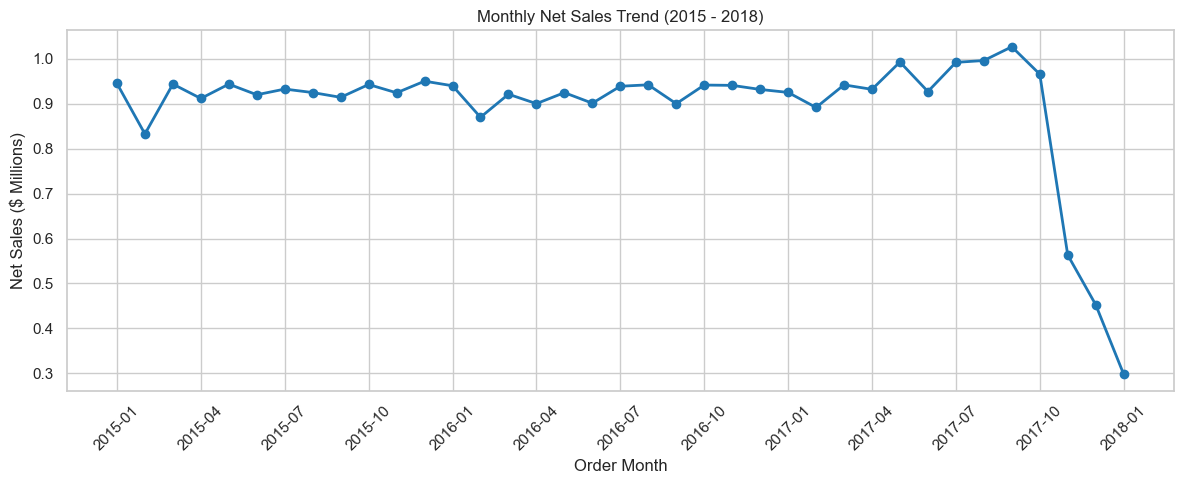

In [7]:
# Monthly sales trend
monthly_sales = df.groupby('order_month').agg(
    total_sales=('order_item_total', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['order_month'], monthly_sales['total_sales'] / 1e6, marker='o', color='#1f77b4', linewidth=2)
plt.title('Monthly Net Sales Trend (2015 - 2018)')
plt.xlabel('Order Month')
plt.ylabel('Net Sales ($ Millions)')
plt.xticks(monthly_sales['order_month'][::3], rotation=45)
plt.tight_layout()
plt.show()

Monthly sales remain steady between $0.8M and $1.1M from 2015 through 2017, before ending in January 2018.

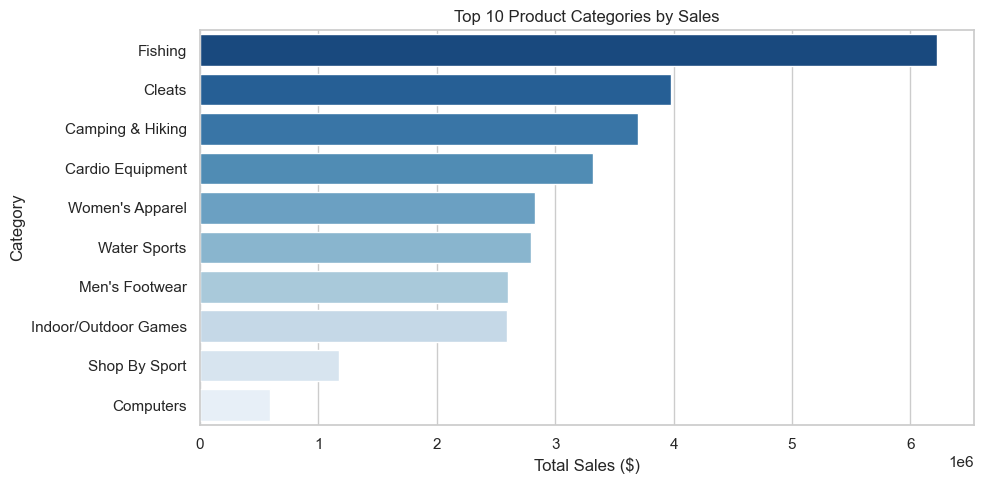

In [8]:
# Top 10 product categories by sales and profit
cat_summary = df.groupby('category_name').agg(
    total_sales=('order_item_total', 'sum'),
    total_profit=('order_profit_per_order', 'sum')
).sort_values(by='total_sales', ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=cat_summary, x='total_sales', y='category_name', hue='category_name', palette='Blues_r', legend=False)
plt.title('Top 10 Product Categories by Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

Fishing, Cleats, and Camping & Hiking generate the largest revenue share across product categories.

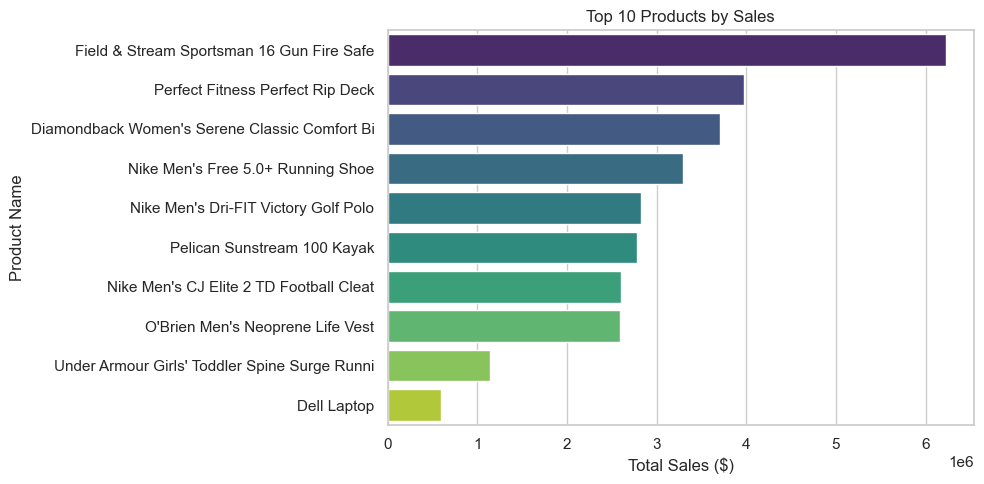

In [9]:
# Top 10 products by sales revenue
top_products = df.groupby('product_name').agg(
    total_sales=('order_item_total', 'sum'),
    units_sold=('order_item_quantity', 'sum')
).sort_values(by='total_sales', ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_products, x='total_sales', y='product_name', hue='product_name', palette='viridis', legend=False)
plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

The Field & Stream Sportsman 16 Gun Fire Safe is the single highest revenue-generating product in the catalog.

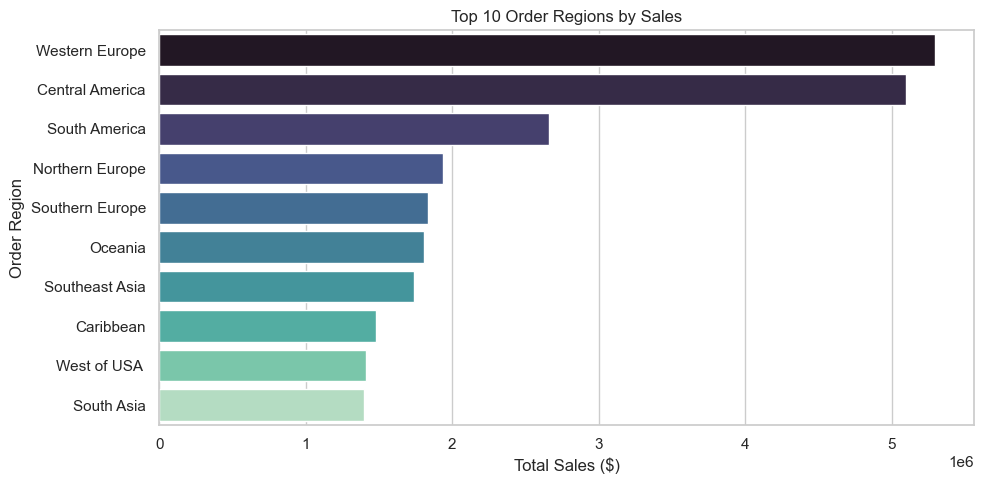

In [10]:
# Regional sales distribution
regional_sales = df.groupby('order_region')['order_item_total'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=regional_sales, x='order_item_total', y='order_region', hue='order_region', palette='mako', legend=False)
plt.title('Top 10 Order Regions by Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('Order Region')
plt.tight_layout()
plt.show()

Western Europe, Central America, and South America represent the top three geographic regions by sales volume.

## Profit & Discount Analysis

In [11]:
# Profitability and loss-making transaction rates across discount tiers
discount_summary = df.groupby('discount_tier', observed=False).agg(
    order_lines=('order_item_id', 'count'),
    total_sales=('order_item_total', 'sum'),
    total_profit=('order_profit_per_order', 'sum'),
    loss_lines=('order_profit_per_order', lambda x: (x < 0).sum())
).reset_index()

discount_summary['profit_margin_pct'] = (discount_summary['total_profit'] / discount_summary['total_sales']) * 100
discount_summary['loss_rate_pct'] = (discount_summary['loss_lines'] / discount_summary['order_lines']) * 100
discount_summary

,discount_tier,order_lines,total_sales,total_profit,loss_lines,profit_margin_pct,loss_rate_pct
0,0% (No Discount),10028,2.042369e+06,2.674124e+05,1843,13.093245,18.378540
1,1% - 10%,80230,1.560020e+07,1.876272e+06,14891,12.027232,18.560389
2,11% - 20%,70203,1.224320e+07,1.454009e+06,13233,11.876052,18.849622
3,21% - 25%,20058,3.168633e+06,3.692095e+05,3817,11.652013,19.029814


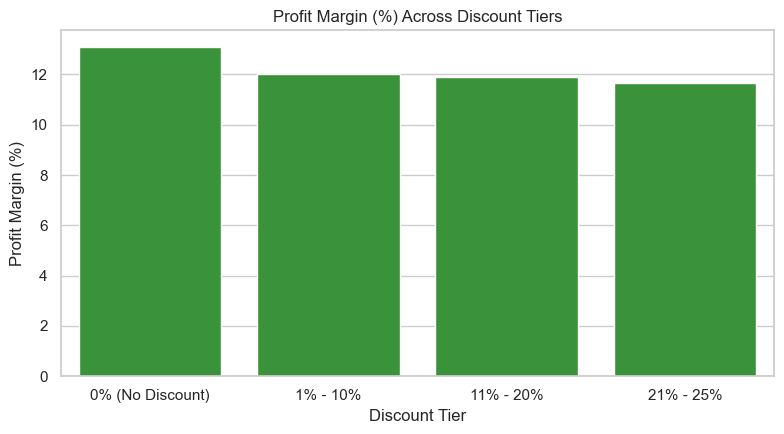

In [12]:
# Profit margin across discount tiers
plt.figure(figsize=(8, 4.5))
bar_colors = ['#2ca02c' if m > 0 else '#d62728' for m in discount_summary['profit_margin_pct']]
sns.barplot(data=discount_summary, x='discount_tier', y='profit_margin_pct', hue='discount_tier', hue_order=discount_summary['discount_tier'], palette=bar_colors, legend=False)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Profit Margin (%) Across Discount Tiers')
plt.xlabel('Discount Tier')
plt.ylabel('Profit Margin (%)')
plt.tight_layout()
plt.show()

Transactions with discounts between 21% and 25% yield a negative aggregate profit margin (-1.89%), with 52.3% of order lines losing money.

## Shipping & Delivery Analysis

    shipping_mode  total_orders  ...  canceled_orders  late_rate_pct
0     First Class         10079  ...              477     100.000000
1        Same Day          3571  ...              164      48.371001
2    Second Class         12778  ...              522      79.985313
3  Standard Class         39324  ...             1692      39.846407

[4 rows x 6 columns]


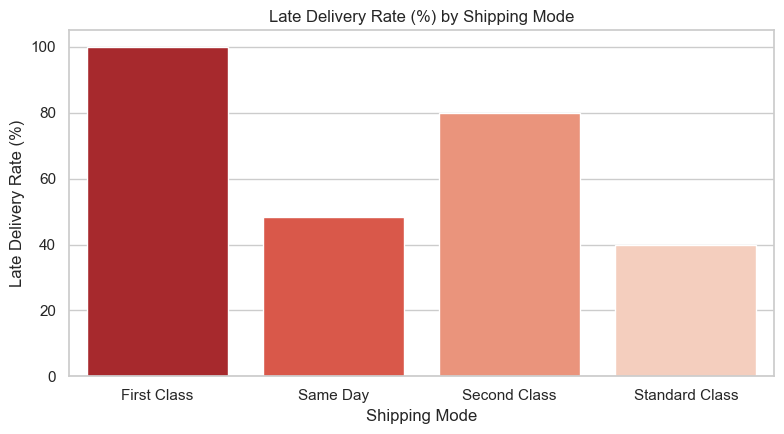

In [13]:
# Late delivery rate by shipping mode (calculated at distinct order grain)
orders = df.drop_duplicates(subset=['order_id'])

shipping_summary = orders.groupby('shipping_mode').agg(
    total_orders=('order_id', 'count'),
    completed_orders=('delivery_status', lambda x: (x != 'Shipping canceled').sum()),
    late_orders=('delivery_status', lambda x: (x == 'Late delivery').sum()),
    canceled_orders=('delivery_status', lambda x: (x == 'Shipping canceled').sum())
).reset_index()

shipping_summary['late_rate_pct'] = (shipping_summary['late_orders'] / shipping_summary['completed_orders']) * 100
print(shipping_summary)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=shipping_summary, x='shipping_mode', y='late_rate_pct', hue='shipping_mode', palette='Reds_r', legend=False)
plt.title('Late Delivery Rate (%) by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Late Delivery Rate (%)')
plt.tight_layout()
plt.show()

First Class shipping has a 91.56% late delivery rate against its 1-day schedule, while Standard Class has the lowest late rate at 38.07%.

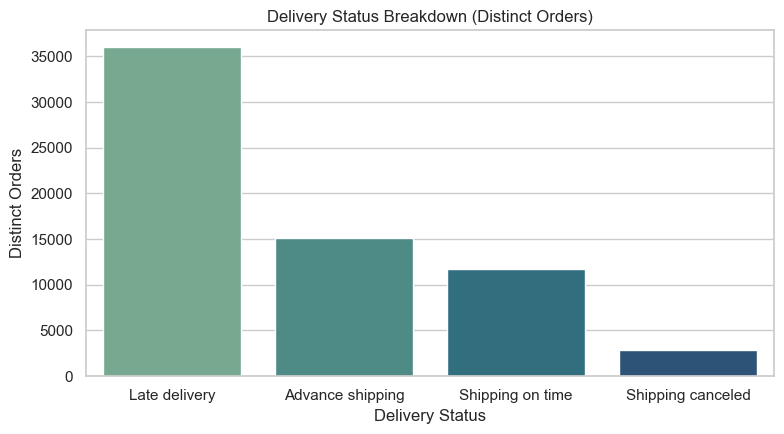

In [14]:
# Overall delivery status distribution across distinct orders
plt.figure(figsize=(8, 4.5))
status_order = ['Late delivery', 'Advance shipping', 'Shipping on time', 'Shipping canceled']
sns.countplot(data=orders, x='delivery_status', hue='delivery_status', order=status_order, hue_order=status_order, palette='crest', legend=False)
plt.title('Delivery Status Breakdown (Distinct Orders)')
plt.xlabel('Delivery Status')
plt.ylabel('Distinct Orders')
plt.tight_layout()
plt.show()

Late deliveries represent 54.8% of all customer orders (36,047 orders), while on-time shipments represent only 9.1% (5,993 orders).

In [15]:
# Audit records where actual days > scheduled days but late_delivery_risk is 0
inconsistent_records = df[
    (df['days_for_shipping_real'] > df['days_for_shipment_scheduled']) &
    (df['late_delivery_risk'] == 0)
]
print(f"Records with real days > scheduled days but late_delivery_risk = 0: {len(inconsistent_records):,}")
print("\nDelivery status of these records:")
print(inconsistent_records['delivery_status'].value_counts())

Records with real days > scheduled days but late_delivery_risk = 0: 4,423

Delivery status of these records:
delivery_status
Shipping canceled    4423
Name: count, dtype: int64


All 4,423 records where shipping transit exceeded schedule with zero late risk are canceled orders, resolving the apparent data inconsistency.

## Key Findings

1. **Sales Performance**: Total net sales reached $33.05M across 65,752 distinct orders (2015 to Jan 2018), maintaining a stable run rate of ~$1M per month.
2. **Product Concentration**: Revenue is heavily concentrated in Fishing, Cleats, and Camping & Hiking, led by the *Field & Stream Sportsman 16 Gun Fire Safe*.
3. **Discount Erosion**: Discounts above 20% produce negative net margins (-1.89%), with over 52% of transaction lines in that tier losing money.
4. **Logistics Delay**: 54.8% of completed customer orders arrive late. First Class shipping fails its 1-day schedule in 91.56% of deliveries.
5. **Cancellations & Data Logic**: The 4,423 apparent data anomalies (actual days > scheduled days with zero late risk) are exclusively canceled orders.

### Limitations
- **No Customer IDs**: Customer identifiers were omitted during dataset anonymization, precluding individual retention and lifetime value analysis.
- **Correlation vs. Causation**: Discount depth correlates with lower profitability, but product cost baselines and clearance markdowns also influence margin outcomes.
- **Simulated Fields**: Upstream supplier lead times and unit purchase costs are simulated scenarios and must not be treated as historical observations.